In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from matplotlib.animation import FuncAnimation, PillowWriter


 1. DISTRIBUCIÓN OBJETIVO p_0(x)
    Mezcla de dos gaussianas en 2D


In [24]:
sigma0 = 0.35

means = np.array([
    [-2.0, 0.0],
    [ 2.0, 0.0]
])

weights = np.array([0.5, 0.5])

2. VP-SDE
dx = -1/2 beta(t) x dt + sqrt(beta(t)) dW

In [25]:

beta_min = 0.1
beta_max = 12.0


def beta(t):

    return beta_min + (beta_max - beta_min) * t


def integral_beta(t):
    """
    Integral desde 0 hasta t de beta(s) ds
    para un beta lineal.
    """

    return (
        beta_min * t
        +
        0.5 * (beta_max - beta_min) * t**2
    )


def alpha_bar(t):

    return np.exp(
        -integral_beta(t)
    )



3. DISTRIBUCIÓN p_t(x)
Si p_0 es una mezcla de gaussianas,
bajo la VP-SDE cada componente sigue siendo gaussiana.

In [26]:

def mixture_parameters_t(t):

    abar = alpha_bar(t)

    # Las medias se acercan al origen
    means_t = np.sqrt(abar) * means

    # La varianza aumenta hacia 1
    variance_t = (
        abar * sigma0**2
        +
        (1.0 - abar)
    )

    return means_t, variance_t

4. DENSIDAD p_t(x)

In [27]:
def density_mixture(x, t):
    """
    x tiene forma (..., 2)
    """

    means_t, variance_t = mixture_parameters_t(t)

    # (..., numero_componentes, 2)
    diff = (
        x[..., None, :]
        -
        means_t
    )

    gaussian_components = (

        np.exp(
            -0.5
            *
            np.sum(diff**2, axis=-1)
            /
            variance_t
        )

        /

        (2 * np.pi * variance_t)
    )

    density = np.sum(
        weights * gaussian_components,
        axis=-1
    )

    return density



5. SCORE ANALÍTICO

score(x,t) = grad_x log p_t(x)


In [28]:
def score_mixture(x, t):
    """
    Score exacto de una mezcla de gaussianas.

    x:
        (..., 2)

    return:
        (..., 2)
    """

    means_t, variance_t = mixture_parameters_t(t)

    diff = (
        x[..., None, :]
        -
        means_t
    )

    # Log-probabilidad de cada componente
    log_components = (

        -0.5
        *
        np.sum(diff**2, axis=-1)
        /
        variance_t

        -

        np.log(
            2 * np.pi * variance_t
        )

        +

        np.log(weights)
    )

    # Responsabilidades de cada gaussiana
    # Se usa esta resta por estabilidad numérica
    max_log = np.max(
        log_components,
        axis=-1,
        keepdims=True
    )

    responsibilities = np.exp(
        log_components - max_log
    )

    responsibilities /= np.sum(
        responsibilities,
        axis=-1,
        keepdims=True
    )

    # Score de cada componente gaussiana
    component_scores = (
        -diff
        /
        variance_t
    )

    # Score total de la mezcla
    score = np.sum(

        responsibilities[..., None]
        *
        component_scores,

        axis=-2
    )

    return score

6. SIMULAR LA REVERSE SDE

Forward:

dx = f(x,t) dt + g(t) dW

con

f = -1/2 beta(t) x
g² = beta(t)


Reverse:

dx =
[f - g² score] dt
+
g dW_bar

Como aquí recorremos t desde 1 -> 0 usando un paso positivo h,
la actualización queda:

x <- x + [-f + g² score] h + g sqrt(h) z

In [29]:
rng = np.random.default_rng(7)

n_particles = 300

n_steps = 300

times = np.linspace(
    1.0,
    0.0,
    n_steps
)

h = 1.0 / (n_steps - 1)


# Empezamos aproximadamente desde el prior N(0,I)
x = rng.normal(
    size=(n_particles, 2)
)


trajectory = []

trajectory.append(
    x.copy()
)


for t in times[:-1]:

    beta_t = beta(t)

    score = score_mixture(
        x,
        t
    )

    # f(x,t) = -1/2 beta(t) x
    #
    # -f + g² score
    # =
    # 1/2 beta x + beta score

    reverse_drift = (

        0.5
        *
        beta_t
        *
        x

        +

        beta_t
        *
        score
    )


    noise = rng.normal(
        size=x.shape
    )


    x = (

        x

        +

        reverse_drift
        *
        h

        +

        np.sqrt(
            beta_t * h
        )
        *
        noise
    )


    trajectory.append(
        x.copy()
    )


trajectory = np.array(
    trajectory
)

7. GRID PARA MOSTRAR p_t(x)

In [30]:
x_grid = np.linspace(
    -4,
    4,
    100
)

y_grid = np.linspace(
    -3,
    3,
    80
)

XX, YY = np.meshgrid(
    x_grid,
    y_grid
)

grid_points = np.stack(
    [XX, YY],
    axis=-1
)

8. GRID PARA LAS FLECHAS DEL SCORE

In [31]:
qx = np.linspace(
    -4,
    4,
    17
)

qy = np.linspace(
    -3,
    3,
    13
)

QX, QY = np.meshgrid(
    qx,
    qy
)

score_grid = np.stack(
    [QX, QY],
    axis=-1
)

9. ANIMACIÓN

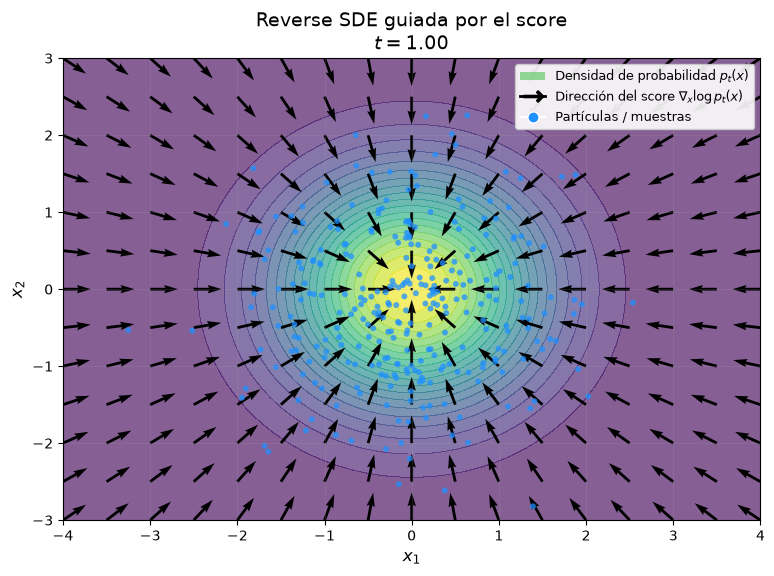

In [32]:

fig, ax = plt.subplots(
    figsize=(9, 6)
)


# No necesitamos mostrar los 300 pasos
# en el GIF.

frame_indices = np.linspace(
    0,
    n_steps - 1,
    90,
    dtype=int
)


def update(frame_number):

    # Limpiar el eje para dibujar el nuevo frame
    ax.clear()

    # --------------------------------------------------------
    # 1. Obtener el instante correspondiente al frame
    # --------------------------------------------------------

    step = frame_indices[frame_number]

    t = times[step]


    # ========================================================
    # 2. DENSIDAD p_t(x)
    # ========================================================

    density = density_mixture(
        grid_points,
        t
    )

    ax.contourf(
        XX,
        YY,
        density,
        levels=25,
        alpha=0.65,
        cmap="viridis"
    )


    # ========================================================
    # 3. CAMPO DEL SCORE
    #
    # s(x,t) = grad_x log p_t(x)
    # ========================================================

    score = score_mixture(
        score_grid,
        t
    )


    # --------------------------------------------------------
    # Normalizar las flechas
    #
    # Esto hace que las flechas representen principalmente
    # la DIRECCIÓN del score y no su magnitud.
    # --------------------------------------------------------

    norm = np.linalg.norm(
        score,
        axis=-1,
        keepdims=True
    )

    score_direction = (
        score
        /
        (norm + 1e-8)
    )


    # --------------------------------------------------------
    # Dibujar flechas del score
    # --------------------------------------------------------

    ax.quiver(
        QX,
        QY,

        score_direction[..., 0],
        score_direction[..., 1],

        angles="xy",
        color="black",

        scale=25,
        width=0.004
    )


    # ========================================================
    # 4. PARTÍCULAS / MUESTRAS
    # ========================================================

    particles = trajectory[
        step
    ]

    ax.scatter(
        particles[:, 0],
        particles[:, 1],

        s=18,
        alpha=0.75,

        color="dodgerblue",
        edgecolors="none"
    )


    # ========================================================
    # 5. LEYENDA / CONVENCIÓN
    # ========================================================

    legend_elements = [

        # Fondo de colores
        Patch(
            facecolor=plt.cm.viridis(0.75),
            edgecolor="none",
            alpha=0.65,
            label=r"Densidad de probabilidad $p_t(x)$"
        ),

        # Flechas negras
        Line2D(
            [0],
            [0],

            color="black",
            linewidth=2,

            marker=r"$\rightarrow$",
            markersize=14,

            label=r"Dirección del score $\nabla_x \log p_t(x)$"
        ),

        # Partículas azules
        Line2D(
            [0],
            [0],

            marker="o",

            color="white",
            markerfacecolor="dodgerblue",

            markersize=8,

            label="Partículas / muestras"
        )
    ]


    ax.legend(
        handles=legend_elements,

        loc="upper right",

        fontsize=9,

        frameon=True,
        framealpha=0.9,

        facecolor="white"
    )


    # ========================================================
    # 6. FORMATO DEL GRÁFICO
    # ========================================================

    ax.set_xlim(
        -4,
        4
    )

    ax.set_ylim(
        -3,
        3
    )


    ax.set_xlabel(
        r"$x_1$",
        fontsize=12
    )

    ax.set_ylabel(
        r"$x_2$",
        fontsize=12
    )


    ax.set_title(
        "Reverse SDE guiada por el score\n"
        +
        rf"$t={t:.2f}$",
        fontsize=14
    )


    # --------------------------------------------------------
    # Cuadrícula opcional
    # --------------------------------------------------------

    ax.grid(
        alpha=0.15
    )


    return []

animation = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=80,
    blit=False
)

10. GUARDAR GIF

In [33]:
animation.save(

    "score_reverse_sde.gif",

    writer=PillowWriter(
        fps=12
    )
)


plt.show()